<a href="https://colab.research.google.com/github/Ahvious/epl-match-prediction/blob/main/AOL_Deep_Learning_(MLP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/EPL_Project"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import numpy as np
import pandas as pd

season_files = {
    "2022-2023": f"{DATA_DIR}/epl_2223.csv",
    "2023-2024": f"{DATA_DIR}/epl_2324.csv",
    "2024-2025": f"{DATA_DIR}/epl_2425.csv",
    "2025-2026": f"{DATA_DIR}/epl2526.csv",
    "2026-2027": f"{DATA_DIR}/epl2627.csv",
}

dfs = []
for season, path in season_files.items():
  df_season = pd.read_csv(path)
  df_season["Season"] = season
  dfs.append(df_season)

df = pd.concat(dfs, ignore_index=True)

core_cols = [
    "Date",
    "Season",
    "HomeTeam",
    "AwayTeam",
    "FTHG",
    "FTAG",
    "FTR",
    "HS",
    "AS",
    "HST",
    "AST",
]
df = df[core_cols].dropna(
    subset=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]
)

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, format="mixed")
df = df.sort_values("Date").reset_index(drop=True)
df["MatchID"] = df.index

home_log = pd.DataFrame({
    "MatchID": df["MatchID"],
    "Date": df["Date"],
    "Team": df["HomeTeam"],
    "IsHome": 1,
    "GoalsFor": df["FTHG"],
    "GoalsAgainst": df["FTAG"],
    "ShotsOnTarget": df["HST"],
    "Points": np.where(df["FTR"] == "H", 3, np.where(df["FTR"] == "D", 1, 0)),
})

away_log = pd.DataFrame({
    "MatchID": df["MatchID"],
    "Date": df["Date"],
    "Team": df["AwayTeam"],
    "IsHome": 0,
    "GoalsFor": df["FTAG"],
    "GoalsAgainst": df["FTHG"],
    "ShotsOnTarget": df["AST"],
    "Points": np.where(df["FTR"] == "A", 3, np.where(df["FTR"] == "D", 1, 0)),
})

team_log = (
    pd.concat([home_log, away_log], ignore_index=True)
    .sort_values(["Team", "Date", "MatchID"])
    .reset_index(drop=True)
)

WINDOW = 5
stats_to_roll = ["GoalsFor", "GoalsAgainst", "ShotsOnTarget", "Points"]

for col in stats_to_roll:
  team_log[f"Roll5_{col}"] = team_log.groupby("Team")[col].transform(
      lambda s: s.shift(1).rolling(window=WINDOW, min_periods=3).mean()
  )

roll_cols = [f"Roll5_{col}" for col in stats_to_roll]

home_features = team_log[team_log["IsHome"] == 1][
    ["MatchID"] + roll_cols
].rename(columns={col: f"Home_{col}" for col in roll_cols})
away_features = team_log[team_log["IsHome"] == 0][
    ["MatchID"] + roll_cols
].rename(columns={col: f"Away_{col}" for col in roll_cols})

dataset = (
    df.merge(home_features, on="MatchID")
    .merge(away_features, on="MatchID")
    .dropna()
    .reset_index(drop=True)
)

dataset.to_csv(f"{DATA_DIR}/epl_mlp_dataset.csv", index=False)
print(f"Saved clean dataset with {len(dataset)} matches.")
print(
    dataset[
        [
            "Date",
            "HomeTeam",
            "AwayTeam",
            "Home_Roll5_GoalsFor",
            "Away_Roll5_GoalsFor",
            "FTHG",
            "FTAG",
        ]
    ].head()
)

Saved clean dataset with 1580 matches.
        Date     HomeTeam     AwayTeam  Home_Roll5_GoalsFor  \
0 2022-08-27  Southampton   Man United             1.666667   
1 2022-08-27    Brentford      Everton             2.666667   
2 2022-08-27     Brighton        Leeds             1.333333   
3 2022-08-27      Chelsea    Leicester             1.000000   
4 2022-08-27    Liverpool  Bournemouth             1.333333   

   Away_Roll5_GoalsFor  FTHG  FTAG  
0             1.000000     0     1  
1             0.666667     1     1  
2             2.333333     1     0  
3             1.666667     2     1  
4             0.666667     9     0  


In [26]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

feature_cols = [
    "Home_Roll5_GoalsFor",
    "Home_Roll5_GoalsAgainst",
    "Home_Roll5_ShotsOnTarget",
    "Home_Roll5_Points",
    "Away_Roll5_GoalsFor",
    "Away_Roll5_GoalsAgainst",
    "Away_Roll5_ShotsOnTarget",
    "Away_Roll5_Points",
]
target_cols = ["FTHG", "FTAG"]

train_df = dataset[dataset["Season"].isin(["2022-2023", "2023-2024", "2024-2025"])]
val_df = dataset[dataset["Season"] == "2025-2026"]
test_df = dataset[dataset["Season"] == "2026-2027"]

X_train, y_train = train_df[feature_cols].values, train_df[target_cols].values
X_val, y_val = val_df[feature_cols].values, val_df[target_cols].values
X_test, y_test = test_df[feature_cols].values, test_df[target_cols].values

print(f"Matches -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(2, activation="softplus"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="poisson",
    metrics=["mae"],
)

model.summary()

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)
preds = model.predict(X_test_scaled)

mlp_mae_home = mean_absolute_error(y_test[:, 0], preds[:, 0])
mlp_mae_away = mean_absolute_error(y_test[:, 1], preds[:, 1])
mlp_mae_total = mean_absolute_error(y_test, preds)

baseline_preds = np.tile(y_train.mean(axis=0), (len(y_test), 1))
base_mae_total = mean_absolute_error(y_test, baseline_preds)

print("\n--- Test Set Evaluation (Season 2026-2027) ---")
print(f"MLP MAE      -> Home: {mlp_mae_home:.4f} | Away: {mlp_mae_away:.4f} | Overall: {mlp_mae_total:.4f}")
print(f"Baseline MAE -> Overall: {base_mae_total:.4f}")

model.save(f"{DATA_DIR}/mlp_premier_league.keras")
joblib.dump(scaler, f"{DATA_DIR}/feature_scaler.pkl")
print(f"\nSaved model and scaler to {DATA_DIR}")

Matches -> Train: 1098 | Val: 377 | Test: 105


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,722 (10.63 KB)

 Trainable params: 2,722 (10.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 1.0317 - mae: 1.0504 - val_loss: 0.9485 - val_mae: 0.9197
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9017 - mae: 1.0235 - val_loss: 0.9385 - val_mae: 0.9177
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8951 - mae: 1.0161 - val_loss: 0.9358 - val_mae: 0.9119
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8765 - mae: 1.0022 - val_loss: 0.9355 - val_mae: 0.9139
Epoch 5/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8713 - mae: 0.9931 - val_loss: 0.9349 - val_mae: 0.9142
Epoch 6/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8711 - mae: 0.9928 - val_loss: 0.9342 - val_mae: 0.9156
Epoch 7/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8700 - mae: 0.9872 - val_loss: 0.9333 - val_mae: 0.9168
Epoch 8/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8713 - mae: 0.9951 - val_loss: 0.9329 - val_mae: 0.9166
Epoch 9/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.85

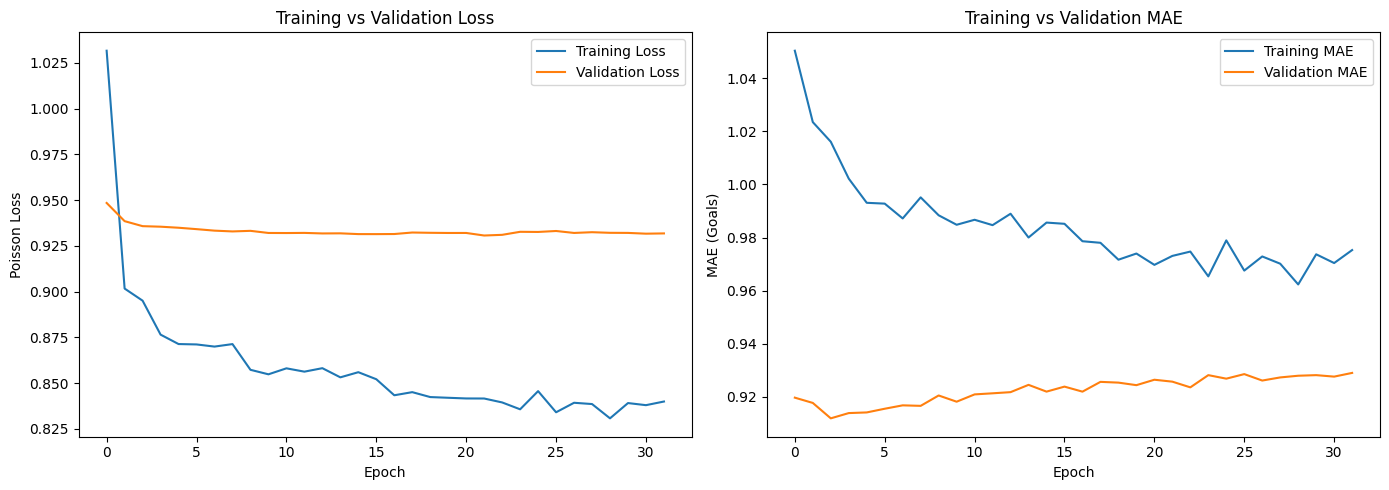

All output sanity checks passed!


,Date,HomeTeam,AwayTeam,FTHG,FTAG,Pred_Home_xG,Pred_Away_xG
1475,2026-08-22,Brentford,Tottenham,3,0,1.47,1.20
1476,2026-08-22,Ipswich,Sunderland,2,1,1.31,1.22
1477,2026-08-22,Nott'm Forest,Leeds,0,1,1.83,1.08
1478,2026-08-22,Everton,Crystal Palace,2,0,1.75,1.28
1479,2026-08-23,Brighton,Aston Villa,4,0,1.64,1.09
1480,2026-08-23,Man City,Bournemouth,2,1,1.62,1.15
1481,2026-08-23,Newcastle,Liverpool,2,2,1.57,1.24
1482,2026-08-24,Fulham,Chelsea,2,3,1.84,1.03
1483,2026-08-28,Crystal Palace,Man City,1,4,0.93,1.77
1484,2026-08-29,Liverpool,Nott'm Forest,2,2,1.54,1.41


In [27]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Poisson Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (Goals)")
plt.title("Training vs Validation MAE")
plt.legend()

plt.tight_layout()
plt.show()

results_preview = test_df[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]].copy()
results_preview["Pred_Home_xG"] = np.round(preds[:, 0], 2)
results_preview["Pred_Away_xG"] = np.round(preds[:, 1], 2)

assert preds.shape == (len(X_test), 2), "Output shape mismatch!"
assert np.all(preds > 0), "Expected goals must be strictly positive for Poisson!"
assert not np.isnan(preds).any(), "Predictions contain NaN!"
print("All output sanity checks passed!")

results_preview.head(10)

In [28]:
home_log_v2 = pd.DataFrame({
    "MatchID": df["MatchID"],
    "Date": df["Date"],
    "Team": df["HomeTeam"],
    "IsHome": 1,
    "GoalsFor": df["FTHG"],
    "GoalsAgainst": df["FTAG"],
    "Shots": df["HS"],
    "ShotsOnTarget": df["HST"],
    "Points": np.where(df["FTR"] == "H", 3, np.where(df["FTR"] == "D", 1, 0)),
})

away_log_v2 = pd.DataFrame({
    "MatchID": df["MatchID"],
    "Date": df["Date"],
    "Team": df["AwayTeam"],
    "IsHome": 0,
    "GoalsFor": df["FTAG"],
    "GoalsAgainst": df["FTHG"],
    "Shots": df["AS"],
    "ShotsOnTarget": df["AST"],
    "Points": np.where(df["FTR"] == "A", 3, np.where(df["FTR"] == "D", 1, 0)),
})

team_log_v2 = (
    pd.concat([home_log_v2, away_log_v2], ignore_index=True)
    .sort_values(["Team", "Date", "MatchID"])
    .reset_index(drop=True)
)

WINDOW = 5
overall_stats = ["GoalsFor", "GoalsAgainst", "Shots", "ShotsOnTarget", "Points"]

for col in overall_stats:
  team_log_v2[f"Roll5_{col}"] = team_log_v2.groupby("Team")[col].transform(
      lambda s: s.shift(1).rolling(window=WINDOW, min_periods=3).mean()
  )

venue_stats = ["GoalsFor", "GoalsAgainst", "Points"]

for col in venue_stats:
  team_log_v2[f"VenueRoll5_{col}"] = team_log_v2.groupby(["Team", "IsHome"])[
      col
  ].transform(lambda s: s.shift(1).rolling(window=WINDOW, min_periods=2).mean())

roll_cols_v2 = [f"Roll5_{c}" for c in overall_stats] + [
    f"VenueRoll5_{c}" for c in venue_stats
]

home_feat_v2 = team_log_v2[team_log_v2["IsHome"] == 1][
    ["MatchID"] + roll_cols_v2
].rename(columns={c: f"Home_{c}" for c in roll_cols_v2})

away_feat_v2 = team_log_v2[team_log_v2["IsHome"] == 0][
    ["MatchID"] + roll_cols_v2
].rename(columns={c: f"Away_{c}" for c in roll_cols_v2})

dataset_v2 = (
    df.merge(home_feat_v2, on="MatchID")
    .merge(away_feat_v2, on="MatchID")
    .dropna()
    .reset_index(drop=True)
)

print(
    f"Iteration 2 dataset ready: {len(dataset_v2)} matches,"
    f" {len(roll_cols_v2) * 2} input features."
)

Iteration 2 dataset ready: 1562 matches, 16 input features.


Epoch 1/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 1.4913 - mae: 1.0758 - val_loss: 1.4156 - val_mae: 0.9537
Epoch 2/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3918 - mae: 1.0498 - val_loss: 1.3685 - val_mae: 0.9460
Epoch 3/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3422 - mae: 1.0458 - val_loss: 1.3360 - val_mae: 0.9403
Epoch 4/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3047 - mae: 1.0334 - val_loss: 1.3092 - val_mae: 0.9353
Epoch 5/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.2828 - mae: 1.0416 - val_loss: 1.2864 - val_mae: 0.9319
Epoch 6/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.2431 - mae: 1.0189 - val_loss: 1.2652 - val_mae: 0.9286
Epoch 7/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.2358 - mae: 1.0392 - val_loss: 1.2460 - val_mae: 0.9256
Epoch 8/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.1935 - mae: 1.0084 - val_loss: 1.2280 - val_mae: 0.9239
Epoch 9/120
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.17

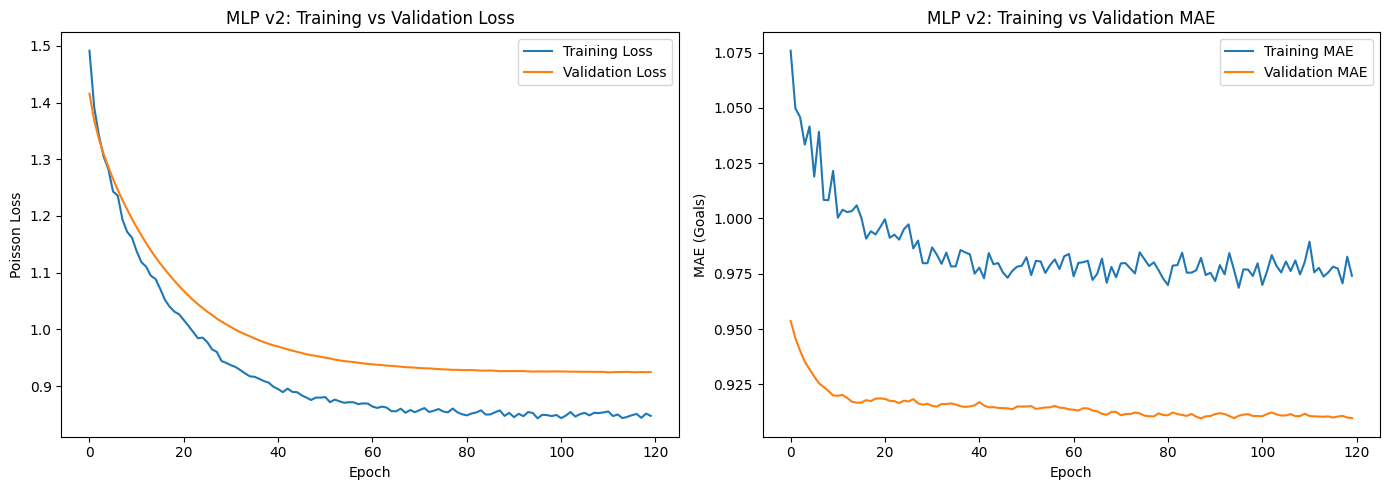

Saved v2 model and scaler to /content/drive/MyDrive/EPL_Project


In [29]:
from tensorflow.keras import regularizers

np.random.seed(42)
tf.random.set_seed(42)

feature_cols_v2 = [f"Home_{c}" for c in roll_cols_v2] + [
    f"Away_{c}" for c in roll_cols_v2
]
target_cols = ["FTHG", "FTAG"]

train_v2 = dataset_v2[
    dataset_v2["Season"].isin(["2022-2023", "2023-2024", "2024-2025"])
]
val_v2 = dataset_v2[dataset_v2["Season"] == "2025-2026"]
test_v2 = dataset_v2[dataset_v2["Season"] == "2026-2027"]

X_tr, y_tr = train_v2[feature_cols_v2].values, train_v2[target_cols].values
X_va, y_va = val_v2[feature_cols_v2].values, val_v2[target_cols].values
X_te, y_te = test_v2[feature_cols_v2].values, test_v2[target_cols].values

scaler_v2 = StandardScaler()
X_tr_s = scaler_v2.fit_transform(X_tr)
X_va_s = scaler_v2.transform(X_va)
X_te_s = scaler_v2.transform(X_te)

model_v2 = keras.Sequential([
    layers.Input(shape=(X_tr_s.shape[1],)),
    layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.2),
    layers.Dense(2, activation="softplus"),
])

model_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="poisson",
    metrics=["mae"],
)

early_stop_v2 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True
)

history_v2 = model_v2.fit(
    X_tr_s,
    y_tr,
    validation_data=(X_va_s, y_va),
    epochs=120,
    batch_size=32,
    callbacks=[early_stop_v2],
    verbose=1,
)

preds_v2 = model_v2.predict(X_te_s)
mae_home_v2 = mean_absolute_error(y_te[:, 0], preds_v2[:, 0])
mae_away_v2 = mean_absolute_error(y_te[:, 1], preds_v2[:, 1])
mae_total_v2 = mean_absolute_error(y_te, preds_v2)

base_v2 = np.tile(y_tr.mean(axis=0), (len(y_te), 1))
base_mae_v2 = mean_absolute_error(y_te, base_v2)

print("\n=== Iteration Comparison (Test Set 2026-2027) ===")
print(f"Baseline MAE : {base_mae_v2:.4f}")
print(f"MLP v1 MAE   : 0.9730  (8 features, 64->32)")
print(
    f"MLP v2 MAE   : {mae_total_v2:.4f}  (16 features, 32->16 + L2) -> Home:"
    f" {mae_home_v2:.4f} | Away: {mae_away_v2:.4f}"
)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_v2.history["loss"], label="Training Loss")
plt.plot(history_v2.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Poisson Loss")
plt.title("MLP v2: Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_v2.history["mae"], label="Training MAE")
plt.plot(history_v2.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (Goals)")
plt.title("MLP v2: Training vs Validation MAE")
plt.legend()
plt.tight_layout()
plt.show()

model_v2.save(f"{DATA_DIR}/mlp_premier_league_v2.keras")
joblib.dump(scaler_v2, f"{DATA_DIR}/feature_scaler_v2.pkl")
print(f"Saved v2 model and scaler to {DATA_DIR}")

In [30]:
import joblib
import numpy as np
import pandas as pd
from tensorflow import keras

team_log_v2.to_csv(f"{DATA_DIR}/latest_team_log_v2.csv", index=False)

loaded_model = keras.models.load_model(
    f"{DATA_DIR}/mlp_premier_league_v2.keras"
)
loaded_scaler = joblib.load(f"{DATA_DIR}/feature_scaler_v2.pkl")
loaded_log = pd.read_csv(f"{DATA_DIR}/latest_team_log_v2.csv")

OVERALL_STATS = ["GoalsFor", "GoalsAgainst", "Shots", "ShotsOnTarget", "Points"]
VENUE_STATS = ["GoalsFor", "GoalsAgainst", "Points"]


def get_latest_team_features(team_name, is_home, log_df):
  """Computes a team's latest 5-match overall and venue-specific averages."""
  team_games = log_df[log_df["Team"] == team_name]
  if team_games.empty:
    available = sorted(log_df["Team"].unique().tolist())
    raise ValueError(
        f"Team '{team_name}' not found. Available teams: {available}"
    )

  overall_vals = team_games.tail(5)[OVERALL_STATS].mean().values

  venue_games = team_games[team_games["IsHome"] == is_home].tail(5)
  if venue_games.empty:
    venue_vals = team_games.tail(5)[VENUE_STATS].mean().values
  else:
    venue_vals = venue_games[VENUE_STATS].mean().values

  return np.concatenate([overall_vals, venue_vals])


def predict_expected_goals(home_team, away_team):
  """
    Handoff function for Monte Carlo Simulation.
    Returns: (home_expected_goals, away_expected_goals) as positive floats.
    """
  home_feats = get_latest_team_features(home_team, is_home=1, log_df=loaded_log)
  away_feats = get_latest_team_features(away_team, is_home=0, log_df=loaded_log)

  X_input = np.concatenate([home_feats, away_feats]).reshape(1, -1)
  X_scaled = loaded_scaler.transform(X_input)

  pred = loaded_model.predict(X_scaled, verbose=0)[0]
  return float(pred[0]), float(pred[1])

home_xg, away_xg = predict_expected_goals("Arsenal", "Liverpool")
print(
    f"Arsenal (Home) xG: {home_xg:.2f} | Liverpool (Away) xG: {away_xg:.2f}"
)

Arsenal (Home) xG: 1.61 | Liverpool (Away) xG: 1.26


In [31]:
def run_mlp_unit_tests():
  print("Running MLP Unit Tests...\n")

  h_xg, a_xg = predict_expected_goals("Man City", "Chelsea")
  assert isinstance(h_xg, float) and isinstance(a_xg, float), (
      "TC-01 Failed: Outputs must be floats"
  )
  assert h_xg > 0 and a_xg > 0, (
      "TC-01 Failed: Expected goals must be > 0 for Poisson"
  )
  assert np.isfinite(h_xg) and np.isfinite(a_xg), (
      "TC-01 Failed: Outputs contain NaN/Inf"
  )
  print(f"[PASS] TC-01: Valid output types & positive range ({h_xg:.2f}, {a_xg:.2f})")

  assert 0.1 <= h_xg <= 5.0 and 0.1 <= a_xg <= 5.0, (
      "TC-02 Failed: Predictions out of realistic range"
  )
  print("[PASS] TC-02: Predictions fall within realistic football xG bounds")

  h_xg_rev, a_xg_rev = predict_expected_goals("Chelsea", "Man City")
  assert (h_xg != h_xg_rev) or (a_xg != a_xg_rev), (
      "TC-03 Failed: Model ignores home/away venue"
  )
  print(
      f"[PASS] TC-03: Venue sensitivity verified (Swapped: {h_xg_rev:.2f},"
      f" {a_xg_rev:.2f})"
  )

  sample_preds_mem = model_v2.predict(X_te_s[:5], verbose=0)
  sample_preds_disk = loaded_model.predict(X_te_s[:5], verbose=0)
  assert np.allclose(sample_preds_mem, sample_preds_disk, atol=1e-5), (
      "TC-04 Failed: Saved model mismatch"
  )
  print("[PASS] TC-04: Saved .keras model matches in-memory model exactly")

  try:
    predict_expected_goals("Fake FC", "Arsenal")
    assert False, "TC-05 Failed: Should have raised ValueError"
  except ValueError:
    print("[PASS] TC-05: Invalid team name handled cleanly with ValueError")

  print("\nAll 5 MLP Unit Tests PASSED!")


run_mlp_unit_tests()

Running MLP Unit Tests...

[PASS] TC-01: Valid output types & positive range (1.72, 1.22)
[PASS] TC-02: Predictions fall within realistic football xG bounds
[PASS] TC-03: Venue sensitivity verified (Swapped: 1.49, 1.45)
[PASS] TC-04: Saved .keras model matches in-memory model exactly
[PASS] TC-05: Invalid team name handled cleanly with ValueError

All 5 MLP Unit Tests PASSED!
